# Detecção de fraude em transações de cartão

**Classificação binária:** identificar transações suspeitas para priorizar revisão humana. `Class=1` indica fraude e `Class=0`, transação legítima.

`Time` representa segundos desde o início da coleta. `V1`–`V28` são variáveis transformadas/anônimas; sua interpretação de negócio é limitada.

**Avaliação:** partição cronológica treino/validação/teste (~70/15/15), mantendo instantes iguais na mesma partição. Transformações ajustadas no treino; seleção do modelo e limiar na validação; avaliação final apenas no teste. Métricas principais: Average Precision (área precisão-recall), precisão, recall, F1/F2 e matriz de confusão.

In [1]:
# Ferramentas: caminhos de arquivos, contas com tabelas, gráficos e modelos de aprendizado.
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, auc, confusion_matrix,
    f1_score, fbeta_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score)

# Número fixo deixa os resultados aleatórios repetíveis.
SEED = 42
# Arquivos de entrada e pasta onde os gráficos serão guardados.
ARQUIVO = Path("data/creditcard.csv")
PASTA_IMAGENS = Path("imagens")
PASTA_IMAGENS.mkdir(exist_ok=True)
# Aparência padrão para os gráficos deste notebook.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["savefig.dpi"] = 160


## 1. Carregamento e qualidade

Inspecionar dimensões, tipos, ausentes, duplicatas, classes e ordenação temporal antes de qualquer preparação.

In [2]:
# Lê o arquivo CSV como uma tabela chamada df.
df = pd.read_csv(ARQUIVO)
# A coluna que queremos adivinhar: 1 significa fraude; 0 significa legítima.
ALVO = "Class"
# Para cedo com erro se o alvo estiver ausente ou tiver rótulos inesperados.
assert ALVO in df and set(df[ALVO].dropna().unique()) <= {0, 1}
# Monta um resumo: tipo de dado, espaços vazios e quantos valores diferentes há.
perfil = pd.DataFrame({"tipo": df.dtypes.astype(str), "ausentes": df.isna().sum(),
                       "valores_unicos": df.nunique(dropna=False)})
# Mostra tamanho da tabela, repetições e duração da coleta.
print(f"{len(df):,} linhas × {len(df.columns)} colunas")
print(f"Duplicadas além da primeira ocorrência: {df.duplicated().sum():,}")
print(f"Time ordenado: {df.Time.is_monotonic_increasing}; período: {df.Time.min():.0f}–{df.Time.max():.0f}s ({df.Time.max()/3600:.1f}h)")
# Exibe o resumo, algumas linhas de exemplo e a quantidade de cada classe.
display(perfil)
display(df.head())
display(df[ALVO].value_counts().rename(index={0:"Legítima",1:"Fraude"}).to_frame("transações"))


284,807 linhas × 31 colunas
Duplicadas além da primeira ocorrência: 1,081
Time ordenado: True; período: 0–172792s (48.0h)


,tipo,ausentes,valores_unicos
Time,float64,0,124592
V1,float64,0,275663
V2,float64,0,275663
V3,float64,0,275663
V4,float64,0,275663
V5,float64,0,275663
V6,float64,0,275663
V7,float64,0,275663
V8,float64,0,275663
V9,float64,0,275663


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,transações
Class,
Legítima,284315
Fraude,492


Não há identificador para saber se uma linha repetida é erro ou uma compra real; por isso, as repetições ficam na análise. Registros do mesmo instante ficam juntos quando separamos os dados. Nesta base não há espaços vazios nem campos de texto que precisem de conversão. Se uma base futura tiver espaços vazios, eles precisarão ser preenchidos antes do treino.


In [3]:
# Conta fraudes, transações legítimas e a parte do total que é fraude.
fraudes = int(df[ALVO].sum())
legitimas = len(df) - fraudes
taxa = fraudes / len(df)
# Compara quantas transações legítimas aparecem para cada fraude.
print(f"Fraudes: {fraudes:,} ({taxa:.3%}); transações legítimas por fraude: {legitimas/fraudes:.1f}:1")
# Confere se há campos vazios ou texto que precisaria ser convertido em números.
print("Ausentes:", int(df.isna().sum().sum()), "| colunas categóricas:", len(df.select_dtypes(exclude=np.number).columns))
# Conta os rótulos nas linhas que fazem parte de algum grupo repetido.
perfis = df[df.duplicated(keep=False)][ALVO].value_counts()
display(perfis.rename(index={0:"Legítima",1:"Fraude"}).to_frame("linhas em grupos repetidos"))


Fraudes: 492 (0.173%); transações legítimas por fraude: 577.9:1
Ausentes: 0 | colunas categóricas: 0


,linhas em grupos repetidos
Class,
Legítima,1822
Fraude,32


## 2. Análise exploratória

Técnicas: perfil/qualidade, frequência do alvo, distribuições, comparação entre classes, correlação e tendência temporal.

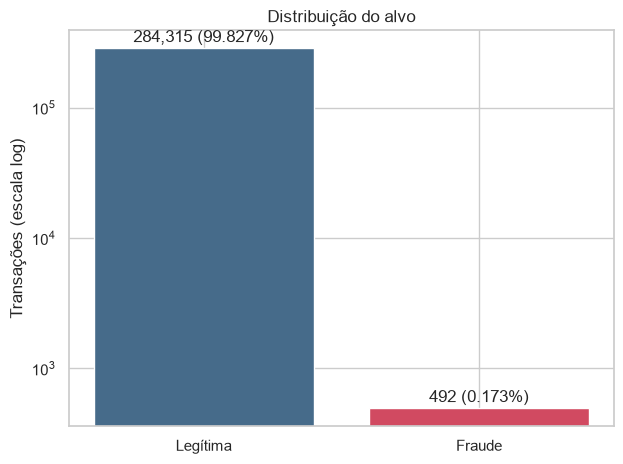

In [4]:
# Conta registros de cada tipo para comparar fraude e transação legítima.
counts = df[ALVO].value_counts().sort_index()
# Prepara a tela e desenha uma barra para cada tipo de transação.
fig, ax = plt.subplots()
ax.bar(["Legítima", "Fraude"], counts.values, color=["#466B8A", "#D14A61"])
# Escala logarítmica ajuda a enxergar a barra pequena das fraudes.
ax.set_yscale("log"); ax.set_ylabel("Transações (escala log)")
ax.set_title("Distribuição do alvo")
# Escreve quantidade e porcentagem acima de cada barra.
for i, v in enumerate(counts): ax.text(i, v*1.12, f"{v:,} ({v/len(df):.3%})", ha="center")
# Ajusta espaços, salva a figura e também a mostra na tela.
fig.tight_layout(); fig.savefig(PASTA_IMAGENS/"01_alvo.png", bbox_inches="tight"); plt.show()


**Insight:** fraude representa menos de 0,2% dos registros. Acurácia isolada pode ser enganosa; avaliar recall e precisão conjuntamente.

,transacoes,media,mediana,p90,maximo
Class,,,,,
Legítima,284315,88.29,22.00,202.72,25691.16
Fraude,492,122.21,9.25,346.75,2125.87


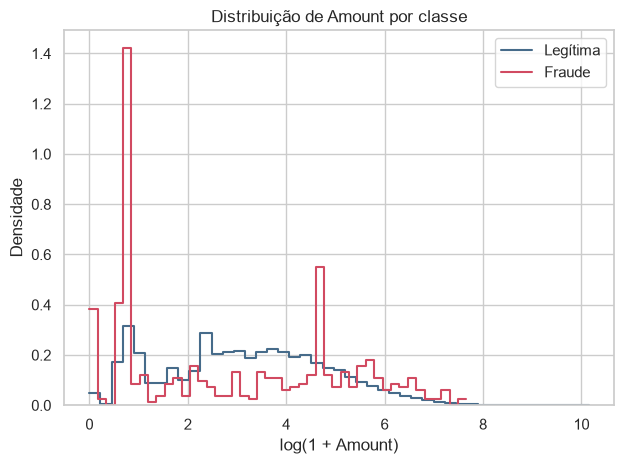

In [5]:
# Separa as transações legítimas e as fraudes para resumir os valores.
grupo_amount = df.groupby(ALVO)["Amount"]
resumo_amount = grupo_amount.agg(["size", "mean", "median", "max"])

# Calcula o valor que 90% das transações daquele grupo não ultrapassam.
percentil_90 = grupo_amount.quantile(0.90)
resumo_amount["p90"] = percentil_90

# Dá nomes mais claros às linhas e colunas da tabela.
resumo_amount = resumo_amount[["size", "mean", "median", "p90", "max"]]
resumo_amount = resumo_amount.rename(columns={
    "size": "transacoes",
    "mean": "media",
    "median": "mediana",
    "max": "maximo",
})
resumo_amount = resumo_amount.rename(index={0: "Legítima", 1: "Fraude"})
display(resumo_amount.round(2))

# Desenha as duas distribuições na mesma figura.
fig, ax = plt.subplots()
for classe, nome, cor in [(0,"Legítima","#466B8A"),(1,"Fraude","#D14A61")]:
    # log1p comprime valores muito altos e permite comparar a forma dos grupos.
    sns.histplot(np.log1p(df.loc[df[ALVO]==classe,"Amount"]), bins=45, stat="density",
        element="step", fill=False, label=nome, color=cor, ax=ax)
# Dá nomes aos eixos e mostra a legenda das cores.
ax.set(xlabel="log(1 + Amount)", ylabel="Densidade", title="Distribuição de Amount por classe")
ax.legend(); fig.tight_layout(); fig.savefig(PASTA_IMAGENS/"02_amount.png", bbox_inches="tight"); plt.show()


**Insight:** `Amount` tem cauda longa e ampla sobreposição entre classes. Diferenças de mediana não justificam, sozinhas, uma regra de fraude.

,|correlação Pearson|
V17,0.326
V14,0.303
V12,0.261
V10,0.217
V16,0.197
V3,0.193
V7,0.187
V11,0.155
V4,0.133
V18,0.111


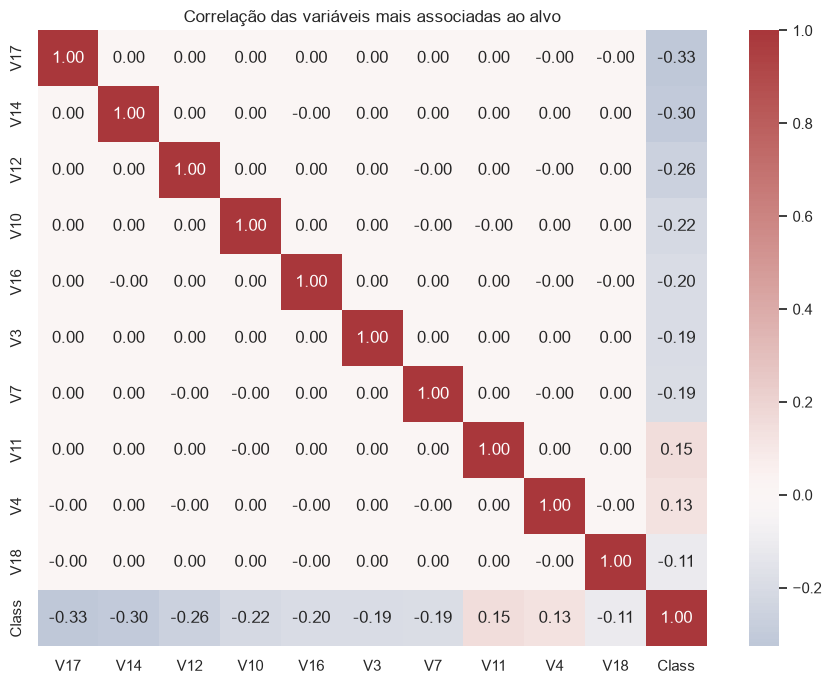

In [6]:
# Mede associação linear de cada coluna com fraude e ordena da maior para a menor.
corr = df.corr(numeric_only=True)[ALVO].drop(ALVO).abs().sort_values(ascending=False)
# Escolhe as dez colunas mais associadas para o gráfico.
cols_corr = corr.head(10).index.tolist()
display(corr.head(10).rename("|correlação Pearson|").to_frame().round(3))
# Mostra como essas colunas se relacionam umas com as outras.
fig, ax = plt.subplots(figsize=(9,7))
sns.heatmap(df[cols_corr+[ALVO]].corr(), cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Correlação das variáveis mais associadas ao alvo")
fig.tight_layout(); fig.savefig(PASTA_IMAGENS/"03_correlacao.png", bbox_inches="tight"); plt.show()


**Insight:** correlação indica associação linear, não causalidade. `V1`–`V28` são transformadas e não permitem explicação direta do comportamento de compra.

,transacoes,fraudes,taxa_pct
janela_h,,,
0,6180,4,0.065
1,3397,34,1.001
2,2763,17,0.615
3,5199,26,0.500
4,13057,20,0.153
5,16805,45,0.268
6,15317,18,0.118
7,15865,27,0.170


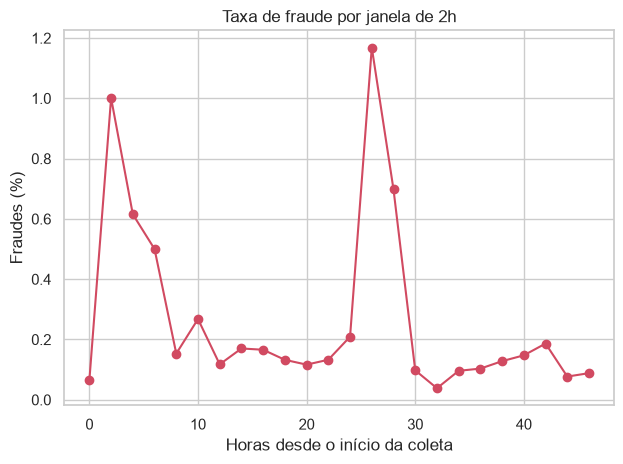

In [7]:
# Separa horário relativo e rótulo; agrupa os registros em blocos de duas horas.
temp = df[["Time",ALVO]].copy(); temp["janela_h"] = (temp.Time//7200).astype(int)
# Conta transações e fraudes em cada bloco de tempo.
serie = temp.groupby("janela_h")[ALVO].agg(transacoes="size",fraudes="sum")
# Converte a contagem em porcentagem para comparar blocos de tamanhos diferentes.
serie["taxa_pct"] = 100*serie.fraudes/serie.transacoes
display(serie.head(8).round(3))
# Desenha como a taxa de fraude muda ao longo das horas observadas.
fig, ax = plt.subplots(); ax.plot(serie.index*2, serie.taxa_pct, marker="o", color="#D14A61")
ax.set(xlabel="Horas desde o início da coleta", ylabel="Fraudes (%)", title="Taxa de fraude por janela de 2h")
fig.tight_layout(); fig.savefig(PASTA_IMAGENS/"04_tempo.png", bbox_inches="tight"); plt.show()


**Insight:** a taxa varia no período observado, mas a base cobre ~48h e não traz horário civil; não sustenta inferência de sazonalidade.

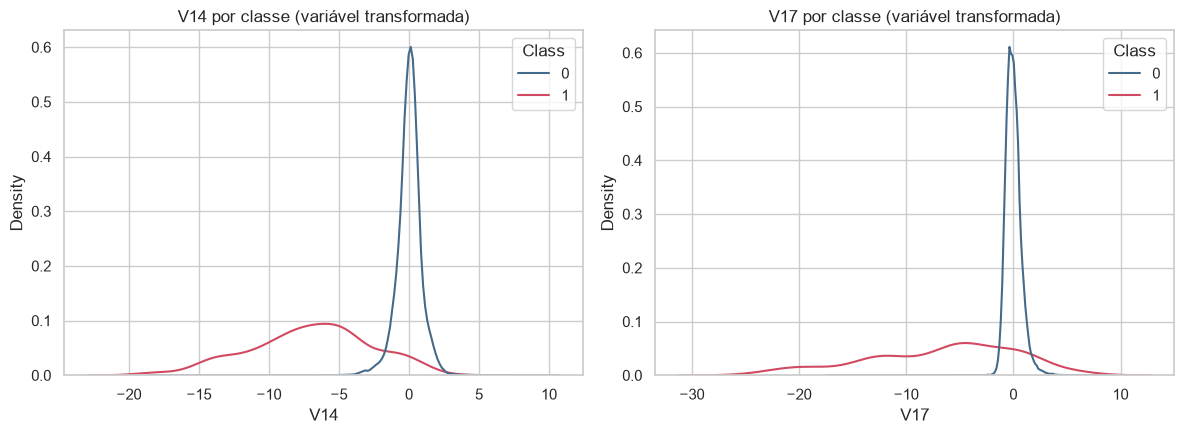

In [8]:
# Prepara dois gráficos lado a lado para comparar variáveis anônimas.
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for ax, col in zip(axes,["V14","V17"]):
    # Desenha a distribuição da variável para fraudes e transações legítimas.
    sns.kdeplot(data=df,x=col,hue=ALVO,common_norm=False,fill=False,
        warn_singular=False,palette={0:"#466B8A",1:"#D14A61"},ax=ax)
    ax.set_title(f"{col} por classe (variável transformada)")
# Ajusta, salva e mostra os dois gráficos.
fig.tight_layout(); fig.savefig(PASTA_IMAGENS/"05_features.png", bbox_inches="tight"); plt.show()


### Síntese da EDA

- A fraude é evento raro (~0,17%); o principal desafio é encontrar positivos mantendo alertas falsos em nível operacional.
- Sem ausentes, colunas constantes ou variáveis categóricas; não é preciso imputar na base atual nem fazer encoding.
- `Amount` tem cauda longa e valores extremos; comparar por classe e usar modelos multivariados.
- `V1`–`V28` mostram associações potencialmente úteis, mas sua anonimização reduz explicabilidade.
- `Time` é ordenado e abrange cerca de dois dias; avaliar em dados posteriores simula melhor o uso futuro.
- Duplicatas foram mantidas por falta de identificador que confirme erro de registro.

## 3. Partição temporal sem vazamento

Separar por `Time` em ~70/15/15, mantendo instantes iguais no mesmo grupo. Aprender a escala usando somente o treino; reaproveitar essa escala na validação e no teste. Não fazer reamostragem.


In [9]:
# Conta registros em cada instante e soma as contagens ao longo do tempo.
contagens_tempo = df.groupby("Time",sort=True).size(); acum = contagens_tempo.cumsum()
# Encontra instantes próximos dos cortes de 70% e 85% da base.
t70 = acum.index[np.searchsorted(acum.to_numpy(), .70*len(df), side="left")]
t85 = acum.index[np.searchsorted(acum.to_numpy(), .85*len(df), side="left")]
# Separa passado para treino, período seguinte para validação e futuro para teste.
treino = df[df.Time<=t70].copy()
valid = df[(df.Time>t70)&(df.Time<=t85)].copy()
teste = df[df.Time>t85].copy()
# Confirma que o teste é posterior à validação, e a validação posterior ao treino.
assert treino.Time.max()<valid.Time.min()<teste.Time.min()
# X contém as pistas; y contém a resposta certa que o modelo deve aprender.
Xtr,ytr=treino.drop(columns=ALVO),treino[ALVO]
Xv,yv=valid.drop(columns=ALVO),valid[ALVO]
Xt,yt=teste.drop(columns=ALVO),teste[ALVO]
# Mostra tamanho, fraudes e intervalo de tempo de cada parte.
display(pd.DataFrame({"linhas":[len(treino),len(valid),len(teste)],
    "fraudes":[ytr.sum(),yv.sum(),yt.sum()],"taxa_fraude_%":[100*ytr.mean(),100*yv.mean(),100*yt.mean()],
    "Time inicial":[treino.Time.min(),valid.Time.min(),teste.Time.min()],
    "Time final":[treino.Time.max(),valid.Time.max(),teste.Time.max()]},
    index=["Treino","Validação","Teste"]).round(3))


,linhas,fraudes,taxa_fraude_%,Time inicial,Time final
Treino,199368,384,0.193,0.0,132929.0
Validação,42718,56,0.131,132930.0,151328.0
Teste,42721,52,0.122,151329.0,172792.0


## 4. Treino e comparação

Comparar regressão logística com ponderação de classes e Random Forest com pesos balanceados. Escolher por Average Precision na validação. Sem busca de hiperparâmetros: resultado comparativo inicial.

,Average Precision,ROC-AUC
modelo,,
Random Forest,0.8697,0.9752
Regressão logística,0.8393,0.9828


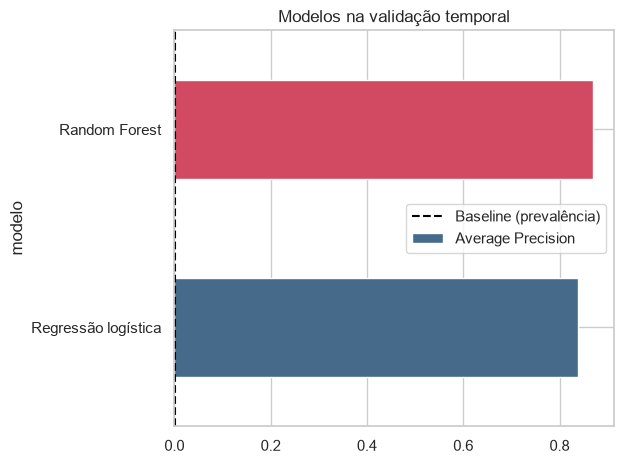

In [10]:
# Padroniza as colunas para a regressão logística, usando apenas os dados de treino.
# Primeiro aprende a escala no treino; depois aplica a mesma escala aos outros dados.
escalador = StandardScaler()
Xtr_escalado = escalador.fit_transform(Xtr)
Xv_escalado = escalador.transform(Xv)
Xt_escalado = escalador.transform(Xt)

# Cria e treina a regressão logística.
modelo_logistico = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=SEED,
)
modelo_logistico.fit(Xtr_escalado, ytr)

# Cria e treina a floresta aleatória com os dados sem escala.
modelo_floresta = RandomForestClassifier(
    n_estimators=160,
    max_depth=14,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=SEED,
)
modelo_floresta.fit(Xtr, ytr)

# Para cada transação da validação, calcula uma chance de ser fraude.
probabilidades_logistico = modelo_logistico.predict_proba(Xv_escalado)[:, 1]
probabilidades_floresta = modelo_floresta.predict_proba(Xv)[:, 1]

# Compara os modelos com as mesmas duas medidas.
comparacao = pd.DataFrame({
    "Average Precision": [
        average_precision_score(yv, probabilidades_logistico),
        average_precision_score(yv, probabilidades_floresta),
    ],
    "ROC-AUC": [
        roc_auc_score(yv, probabilidades_logistico),
        roc_auc_score(yv, probabilidades_floresta),
    ],
}, index=["Regressão logística", "Random Forest"])
comparacao = comparacao.sort_values("Average Precision", ascending=False)
display(comparacao.round(4))

# Compara as pontuações; a linha tracejada mostra a taxa de fraude na validação.
fig, ax = plt.subplots()
comparacao["Average Precision"].sort_values().plot.barh(
    ax=ax, color=["#466B8A", "#D14A61"]
)
ax.axvline(yv.mean(), color="black", linestyle="--", label="Baseline (prevalência)")
ax.set_title("Modelos na validação temporal")
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_IMAGENS/"06_modelos.png", bbox_inches="tight")
plt.show()


## 5. Limiar e avaliação final

Sem custos fornecidos, escolher limiar que maximiza F2 na validação (favorece recall). Não é política de produção; avaliar impacto operacional antes de bloquear transações.

In [11]:
# Pega o nome do modelo com maior Average Precision na validação.
nome_final = comparacao.index[0]

# Usa o modelo vencedor para calcular as chances de fraude na validação e no teste.
if nome_final == "Regressão logística":
    probabilidades_validacao = probabilidades_logistico
    probabilidades_teste = modelo_logistico.predict_proba(Xt_escalado)[:, 1]
else:
    probabilidades_validacao = probabilidades_floresta
    probabilidades_teste = modelo_floresta.predict_proba(Xt)[:, 1]

# Testa diferentes limites: acima do limite, a transação vira um alerta.
precisoes, recalls, limites = precision_recall_curve(yv, probabilidades_validacao)

# Calcula F2 para cada limite; essa medida dá mais peso a encontrar fraudes.
f2 = 5 * precisoes[:-1] * recalls[:-1] / (
    4 * precisoes[:-1] + recalls[:-1] + 1e-12
)
posicao_melhor = int(np.nanargmax(f2))
limiar = float(limites[posicao_melhor])

print(f"Selecionado: {nome_final} | limiar: {limiar:.6f}")
print(
    f"Validação: precisão={precisoes[posicao_melhor]:.3f}, "
    f"recall={recalls[posicao_melhor]:.3f}, F2={f2[posicao_melhor]:.3f}"
)

# Compara as chances do teste com o limite escolhido na validação.
pred = (probabilidades_teste >= limiar).astype(int)
matriz = confusion_matrix(yt, pred, labels=[0, 1])
negativos_corretos, alertas_falsos, fraudes_perdidas, fraudes_detectadas = matriz.ravel()

# Resume a qualidade das previsões feitas para o período de teste.
metricas = {
    "Average Precision": average_precision_score(yt, probabilidades_teste),
    "ROC-AUC": roc_auc_score(yt, probabilidades_teste),
    "Precisão": precision_score(yt, pred, zero_division=0),
    "Recall": recall_score(yt, pred, zero_division=0),
    "F1": f1_score(yt, pred, zero_division=0),
    "F2": fbeta_score(yt, pred, beta=2, zero_division=0),
    "Limiar": limiar,
    "Fraudes detectadas": fraudes_detectadas,
    "Alertas falsos": alertas_falsos,
    "Fraudes perdidas": fraudes_perdidas,
    "Negativos corretos": negativos_corretos,
}
display(pd.Series(metricas, name="teste temporal").to_frame().round(4))
print(f"Detectadas {fraudes_detectadas} de {fraudes_detectadas + fraudes_perdidas} fraudes; {alertas_falsos} alertas falsos.")


Selecionado: Random Forest | limiar: 0.143069
Validação: precisão=0.857, recall=0.857, F2=0.857


,teste temporal
Average Precision,0.7733
ROC-AUC,0.9570
Precisão,0.6842
Recall,0.7500
F1,0.7156
F2,0.7358
Limiar,0.1431
Fraudes detectadas,39.0000
Alertas falsos,18.0000
Fraudes perdidas,13.0000


Detectadas 39 de 52 fraudes; 18 alertas falsos.


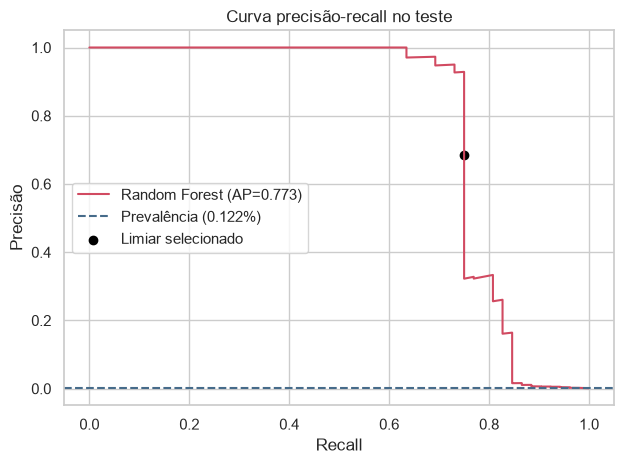

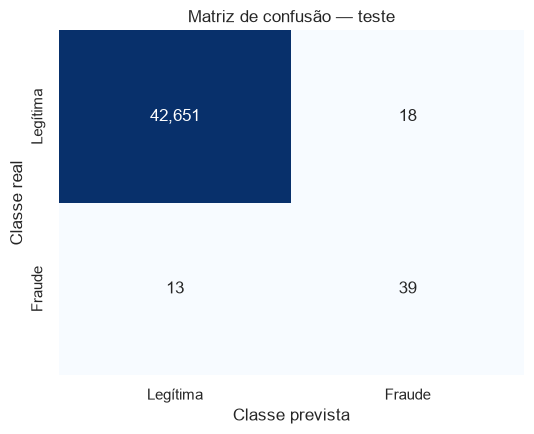

In [12]:
# Calcula precisão e recall para diferentes limites no conjunto de teste.
precisoes_teste, recalls_teste, _ = precision_recall_curve(yt, probabilidades_teste)
ap_teste = average_precision_score(yt, probabilidades_teste)

# Desenha a curva: cada ponto mostra o equilíbrio entre precisão e recall.
fig, ax = plt.subplots()
ax.plot(
    recalls_teste,
    precisoes_teste,
    color="#D14A61",
    label=f"{nome_final} (AP={ap_teste:.3f})",
)

# A linha mostra a taxa de fraude; serve como comparação simples.
ax.axhline(
    yt.mean(),
    color="#466B8A",
    linestyle="--",
    label=f"Prevalência ({yt.mean():.3%})",
)

# O ponto preto mostra o resultado no limite escolhido na validação.
recall_no_limite = recall_score(yt, pred, zero_division=0)
precisao_no_limite = precision_score(yt, pred, zero_division=0)
ax.scatter(recall_no_limite, precisao_no_limite, color="black", label="Limiar selecionado")
ax.set(xlabel="Recall", ylabel="Precisão", title="Curva precisão-recall no teste")
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_IMAGENS/"07_pr.png", bbox_inches="tight")
plt.show()

# Desenha a matriz: linhas são a resposta real; colunas são o palpite do modelo.
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    matriz,
    annot=True,
    fmt=",",
    cmap="Blues",
    cbar=False,
    xticklabels=["Legítima", "Fraude"],
    yticklabels=["Legítima", "Fraude"],
    ax=ax,
)
ax.set(xlabel="Classe prevista", ylabel="Classe real", title="Matriz de confusão — teste")
fig.tight_layout()
fig.savefig(PASTA_IMAGENS/"08_confusao.png", bbox_inches="tight")
plt.show()


**Interpretação:** precisão estima quantos alertas são fraudes; recall estima quantas fraudes observadas foram detectadas. Falso positivo consome capacidade de revisão e pode gerar atrito; falso negativo deixa fraude sem sinalização. Use limiar F2 apenas como ponto inicial enquanto custos e capacidade da operação não forem definidos.

,importância interna
V14,0.1696
V10,0.1423
V12,0.1116
V17,0.0972
V4,0.0925
V16,0.0553
V11,0.0526
V3,0.0485
V2,0.0297
V7,0.0291


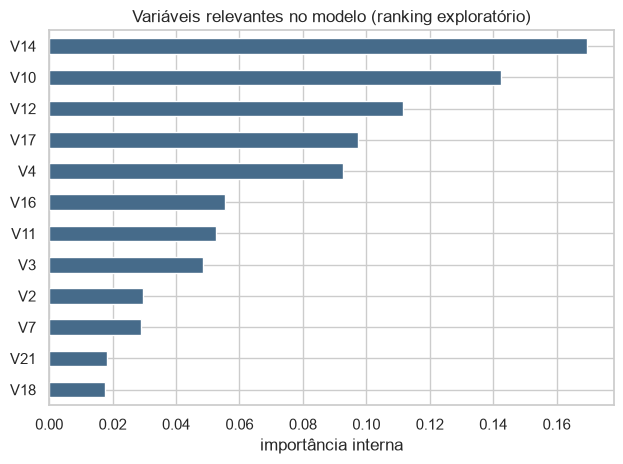

In [13]:
# Olha dentro do modelo selecionado para ver quais colunas mais ajudaram.
if nome_final == "Regressão logística":
    # Peso maior significa que a coluna teve mais influência na conta do modelo.
    importancia = pd.Series(
        np.abs(modelo_logistico.coef_[0]),
        index=Xtr.columns,
        name="|coeficiente|",
    )
else:
    # Na floresta, mede quantas vezes cada coluna ajudou a separar os casos.
    importancia = pd.Series(
        modelo_floresta.feature_importances_,
        index=Xtr.columns,
        name="importância interna",
    )

# Mostra só as 12 colunas mais importantes para facilitar a leitura.
importancia = importancia.sort_values(ascending=False).head(12)
display(importancia.to_frame().round(4))

# Desenha o ranking; associação não quer dizer que uma coluna causou a fraude.
fig, ax = plt.subplots()
importancia.sort_values().plot.barh(ax=ax, color="#466B8A")
ax.set(xlabel=importancia.name, title="Variáveis relevantes no modelo (ranking exploratório)")
fig.tight_layout()
fig.savefig(PASTA_IMAGENS/"09_importancia.png", bbox_inches="tight")
plt.show()


## 6. Conclusão e recomendação

O modelo foi escolhido na validação temporal e avaliado em transações posteriores. A janela de ~48 horas e o baixo número de fraudes limitam a generalização. Use o resultado como **triagem para revisão humana**, não como bloqueio automático. Para decidir operação, definir custo de fraude, capacidade de investigação e tolerância a falsos positivos; então selecionar limiar pela curva precisão-recall. Validar em período mais longo e monitorar mudança da prevalência.

`V1`–`V28` têm capacidade preditiva, mas não explicação de domínio disponível. Importância do modelo é associação preditiva, não causalidade.

As nove figuras geradas pelo notebook estão em `imagens/`.